9) 비지도학습 군집
- 비지도학습(Unsupervised Learning)은 정답이 없는 데이터를 학습하여 데이터의 패턴이나 구조를 찾는 방법이다.
- 군집화(Clustering)는 데이터의 유사성을 바탕으로 비슷한 데이터끼리 그룹으로 묶는 기법이다.
- 대표 알고리즘: K-Means, DBSCAN, 계층적 군집화

#### 군집 후 보통 사람이 직접 군집별 해석

① 군집별 통계 → ② 전체 평균과 비교 → ③ 특징 해석 → ④ 군집 이름 부여 → ⑤ 마케팅 전략 결정
- y가없는 표형태의 정형데이터는 바로 군집 가능
- 이미지 같은 비정형데이터는 숫자형태의 특징으로 변환한 뒤 군집
- 실무에서 이미지 데이터셋은  군집보다는 대체로 사람이 라벨링(눈으로 확인 후 정답 y입력이 가능하므로)  → 지도학습(분류/객체탐지 등)이 기본적인 흐름이다.

예를 들면
1. 이미지 수집 → 사과/바나나 사진 10,000장 수집
2. 사람이 애노테이션 → 사과, 바나나 라벨 부여 → 객체탐지라면 물체 위치까지 박스로 표시
3. 학습 데이터 구성 → 이미지 + 정답(label)
4. 딥러닝 모델 학습 → CNN, ResNet, YOLO 등으로 학습
5. 새로운 이미지 예측 → "이 이미지는 사과일 확률 95%"

군집학습은 정답이 없는 데이터에서 유사한 데이터끼리 그룹화하는 비지도학습이다. <br>
수업에서는 군집 학습 후 군집 결과가 적절했는지 확인하기 위해 정답을 알고 있는 이미지 데이터셋과 분류에 사용하는 sklearn iris 샘플데이터셋을 사용하지만, <br>
실제 군집학습은 정답이 없는 데이터셋에 사용하기 위함이다. <br>

- 수업 실습: 이미지의 종류를 알고 있으므로 군집 결과와 실제 종류를 비교하여 군집이 적절한지 확인한다.
- 실무 활용: 고객 구매 데이터, 뉴스 기사, 상품 데이터 등 정답이 없는 데이터에 군집화를 적용한다.
- 군집 평가: 정답이 없어도 실루엣 계수(Silhouette Score) 등을 이용해 군집의 응집도와 분리도를 평가할 수 있다.

```text
[실습 1]
100×100 픽셀을 숫자0과 0이 아닌수로 네모,세모를 표현한 데이터셋 60개, 60×100×100의 3차원 배열 이다

예시: 5 × 5로 세모
0 0 0 0 0
0 0 1 0 0
0 1 1 1 0
1 1 1 1 1
0 0 0 0 0

   ●
  ●●●
 ●●●●●

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 넘파이 배열 파일 불러오기
loaded_arr = np.load("shapes_data.npy")

# 형태(shape) 확인
print(loaded_arr.shape)  # 출력: (60, 100, 100) -> 60개의 100픽셀 x 100픽셀 이미지 데이터
print(len(loaded_arr)) 

(60, 100, 100)
60


In [6]:
print(loaded_arr[0]) # 0~29 실제이미지 네모
display(loaded_arr[0])
print(loaded_arr[30]) # 30~59 실제이미지 세모
display(loaded_arr[30])
# NumPy배열의 요소가 많으면 출력 시간이 길어지고 화면이 커질 수 있어 중간 요소값을 생략하고 출력하는 옵션이 기본값으로 설정되어 있다.

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(100, 100), dtype=uint8)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(100, 100), dtype=uint8)

In [7]:
# NumPy 배열의 생략을 방지하려면 np.set_printoptions()를 사용한다.
import numpy as np
np.set_printoptions(threshold=np.inf)
print(loaded_arr[0]) 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0 

In [8]:
# 생략 설정을 원래대로(기본값으로) 변경하려면 다음과 같이 실행한다.
np.set_printoptions(threshold=1000)
print(loaded_arr[0]) 

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [13]:
# 3차원 데이터를 2차원으로 변경(입력값이 2차원 형태를 입력받음)으로 K-Means 군집화 모델을 이용하여 학습

# 2. K-Means 군집화 수행
# X = loaded_arr.reshape(60, 10000) # loaded_arr[0][0][0] ~ loaded_arr[59][99][99]
# 60 -> len(loaded_arr), loaded_arr.shape[0]
# 10000 -> 남은건 자동으로 계산 -1
X = loaded_arr.reshape(loaded_arr.shape[0], -1)
print(X.shape) # 60*100*100 -> 60*10000 X[0][0] ~ X[59][9999]
# -1은 남은 차원값을 알아서 계산해서 넣음 count가 60이니, 100, 100인 자동계산 후 10000으로 입력

kmeans = KMeans(n_clusters=2, random_state=1) # 2개로 클러스터(군집)

# kmeans = KMeans(n_clusters=3, random_state=1) 
# 데이터를 3개로 클러스터, 세모클래스 비슷한데, 네모클래스가 두클래스로 클러스터됨 

cluster_labels = kmeans.fit_predict(X) # 학습 후 결과 반환
# 아래와 동일한 코드
# kmeans.fit(X) # 학습
# cluster = kmeans.labels_ # 결과 저장

print(cluster_labels) # 정답이 없는 데이터를 2개로 분류하라고 했으니 데이터에 특성에 따라 0, 1로 분류



(60, 10000)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


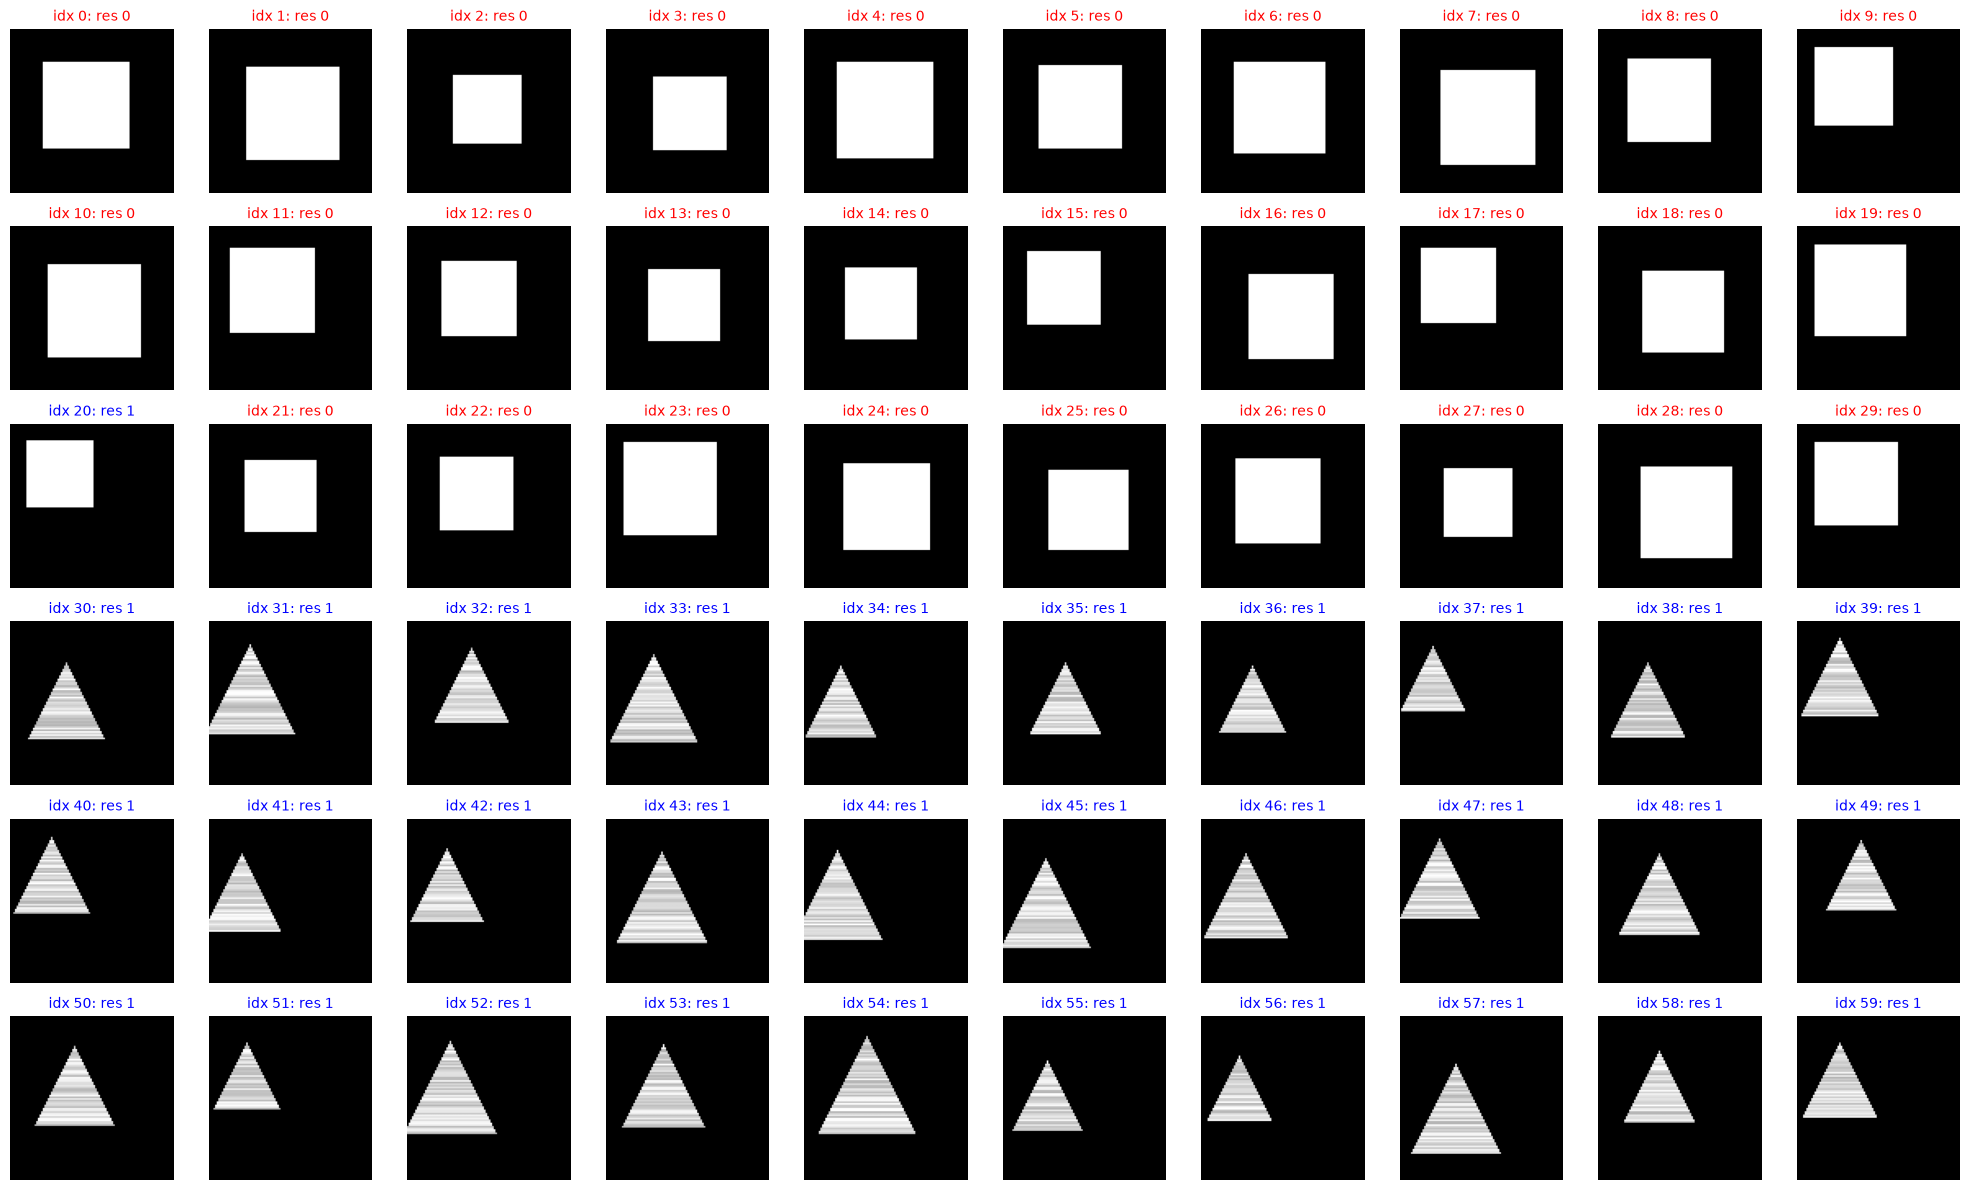

In [15]:
# 인덱스 20번째 하나만 네모를 세모로 클러스터, 실제 이미지로 확인

# 1. 6행 10열 그리드 서브플롯 생성 (총 60개)
fig, axes = plt.subplots(6, 10, figsize=(20, 12))

# 2. (6, 10) 형태의 2차원 축 배열을 1차원(60,)으로 변환하여 순회 용이하게 처리
axes = axes.flatten()

# 3. 60개 이미지 순회 출력
for i in range(60):
    ax = axes[i]
    ax.imshow(loaded_arr[i], cmap='gray')
    
    # 군집 번호 및 색상 설정
    c = cluster_labels[i]
    color = "red" if c == 0 else "blue"
    
    # 서브플롯 제목 표시
    ax.set_title(f'idx {i}: res {c}', color=color, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

※ 네모와 세모 이미지 군집화에서는 이미지를 픽셀값으로 변환한 후 K-Means를 사용하여 비슷한 이미지끼리 그룹화했다. <br>
개와 고양이 이미지도 원리는 동일하다. 컴퓨터는 이미지를 사람처럼 이해하지 못하므로 이미지를 숫자 데이터로 변환해야 한다. <br>
다만 네모와 세모처럼 단순한 이미지는 픽셀값만으로도 구분할 수 있지만, 개와 고양이처럼 복잡한 이미지는 픽셀값만으로 구분하기 어렵다. <br>
따라서 CNN과 같은 딥러닝 모델을 이용해 이미지의 특징을 숫자 데이터로 추출한 후, K-Means로 비슷한 이미지끼리 그룹화할 수 있다. <br>
핵심은 이미지의 종류와 관계없이 숫자 데이터로 변환하여 군집화한다는 점이다. 다만 복잡한 이미지일수록 이미지의 특징을 효과적으로 추출하는 과정이 중요하다. <br>

[실습 2] <br>
지도 분류 학습용 데이터셋 iris의 정답특성(3클래스)을 삭제하고, k=3으로 K-means 비지도 군집 학습 <br>
정답을 모르는데, K=3을 무슨근거로 후보로 선택? <br>
보통 엘보우 방법을 이용하여, K=2, 3, 4, 5…로 루프로 실행 후 군집 내 거리의 합이 급격히 줄어드는 지점 확인꺾이는 지점을 K로 선택한다. 자세한 방법은 알고리즘 수업에서 학습한다. <br>

변수의 수가 적다면 산점도 같은 시각화 탐색도 가능. <br>
다만 중요한 점은 정답이 없으므로 K=3이 '진짜 정답'이라고 확정하는 것은 아닙니다. <br>
지도의 분류는 정확한가? 정확성을 평가 <br>
비지도의 군집은 적절한가? 적절성을 해석 <br>

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


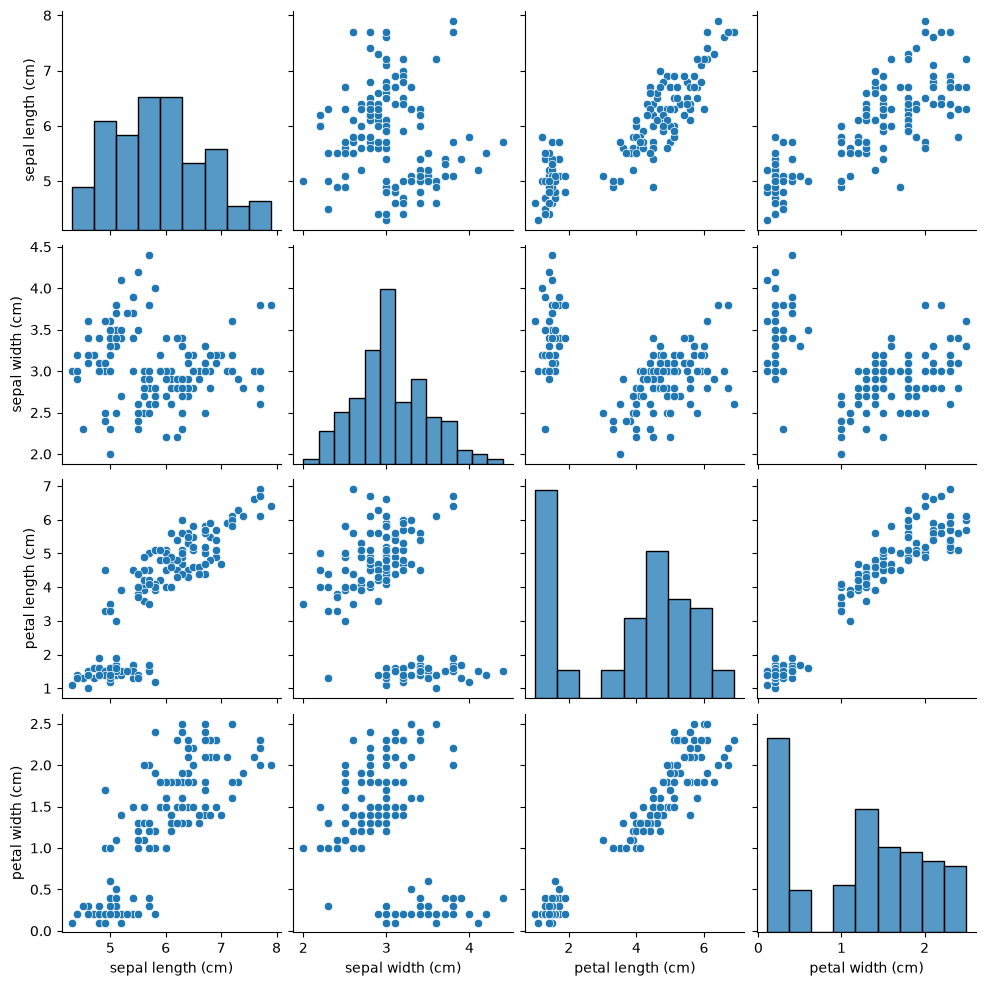

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. 데이터 로드
# as_frame=True numpy  판다스(데이터프레임, 시리즈)타입으로 로드, 기본값은 넘파이배열타입
# pairplot()dm으로 산점도 행열을 출력하려면 데이터프레임 타입이 필요
iris = load_iris(as_frame=True) 
X = iris.data  # 정답 특성 target 제외

display(X.head())

# 2. 산점도로 데이터 분포 탐색
sns.pairplot(X) # 앞서 X를 데이터프레임 타입으로 로드한 이후, 배열타입이면 pairplot()함수를 바로 사용할 수 없다 

# 3. 표준화: Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# y = iris.target # 지도학습 군집이면 실제로는 존재하지 않는 데이터

# 4. K-means 군집 학습
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster = kmeans.fit_predict(X_scaled)

In [2]:
# 5. 원본 데이터 + 군집 결과 + 실제 정답 비교
print(cluster)
print(type(iris.target))
# 시리즈 타입이라 비교가 힘들어 넘파이 배열로 변경 후 출력 0, 1, 2값은 다룰 수 있음. 군집을 비교
print(iris.target.to_numpy()) 

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
<class 'pandas.Series'>
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
